In [1]:
import pandas as pd
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv("gamm_predictions_all.csv")

In [3]:
def get_tone_value(pair, portion_idx, lang):
    if portion_idx<=10:
        pos = "preceding"
    else:
        pos = "following"
    if lang.startswith("man"):
        if pos=="preceding":
            tone = pair.split("-")[0]
        elif pos=="following":
            tone = pair.split("-")[1]
        if pair=="3-3" and pos=="preceding":
            return "35", "T3'"
        else:
            return {"1": "55", "2": "35", "3": "21", "4": "51"}[tone], f"T{tone}"
    
    if lang=="min":
        if pos=="preceding":
            if " |" in pair:
                return pair.split(" |")[-1], "T5'"

            tone = pair.split("-")[0]
            return {"1": "33", "2": "55", "3": "51", "7": "21"}[tone], f"T{tone}'"
        elif pos=="following":
            tone = pair.split("-")[1][0]
            return {"1": "55", "2": "51", "3": "21", "5": "35", "7": "33"}[tone], f"T{tone}"
    raise NotImplementedError

In [4]:
tone_values = []
tone_labels = []

for pair, portion_idx, lang in zip(df["pair"], df["portion_idx"], df["lang"]):
    tone_value, tone_label = get_tone_value(pair, portion_idx, lang)
    tone_values.append(tone_value)
    tone_labels.append(tone_label)


In [5]:
df["tone_value"] = tone_values
df["tone_label"] = tone_labels

In [6]:
sns.set_style("whitegrid")
sns.set_style({"font.family": "serif", "font.serif": ["Times New Roman"]})
palette = sns.color_palette("muted")
colors = {
    "55": palette[0],
    "51": palette[2],
    "35": palette[1],
    "33": palette[3],
    "21": palette[4],
}

In [7]:
def modify_color(color):
    return (color[0]*.9, color[1]*.8, color[2]*.85)

/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/546642017.py:31: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/546642017.py:31: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/546642017.py:31: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/546642017.py:31: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):


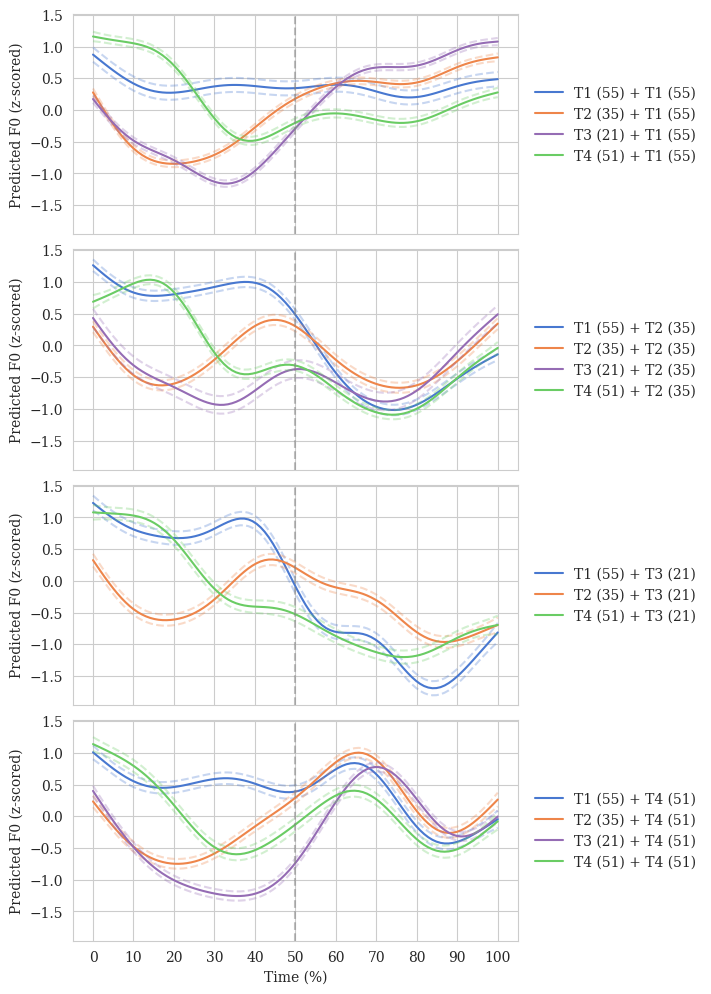

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

lang = "man"
position = "carryover"
fig, axes = plt.subplots(4, 1, figsize=(6, 10), sharex=True, sharey=True)

preceding_tone_values = df[
    (df.lang == lang) &
    (df.position == position) &
    (df.portion_idx<=10)
]["tone_value"].unique()

following_tone_values = df[
    (df.lang == lang) &
    (df.position == position) &
    (df.portion_idx>10)
]["tone_value"].unique()

for idx, target_tone_value in enumerate(following_tone_values):
    this_df = df[
        (df.lang == lang) &
        (df.position == position) &
        (df.tone_value == target_tone_value)
    ]

    legend_handles = []
    legend_labels = []
    used_colors = []

    for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):

        this_df = df[
            (df.lang == lang) &
            (df.position == position) &
            (df.pair == pair)
        ]

        target_tone_value = this_df[(this_df["portion_idx"]>10)]["tone_value"].values[0]
        target_tone_label = this_df[(this_df["portion_idx"]>10)]["tone_label"].values[0]
        context_tone_value = this_df[(this_df["portion_idx"]<=10)]["tone_value"].values[0]
        context_tone_label = this_df[(this_df["portion_idx"]<=10)]["tone_label"].values[0]
        color = colors[context_tone_value]
        if color in used_colors:
            color = modify_color(color)
        used_colors.append(color)

        line = sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y="fit",
            color=color,
            label=f"{context_tone_label} ({context_tone_value}) + {target_tone_label} ({target_tone_value})",
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit+se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit-se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )

        handle, label = line.get_legend_handles_labels()
        if label and label[0] not in legend_labels:
            legend_handles += handle
            legend_labels += label
            
        axes[idx].set_ylabel("Predicted F0 (z-scored)")


    axes[idx].axvline(x=21/2, color="gray", linestyle="--", alpha=.5)
    axes[-1].set_xlabel("Time (%)")
    axes[-1].set_xticks(np.arange(0, 21+2.1, 2.1))
    axes[-1].set_xticklabels(["0", "10", "20", "30", "40", "50", "60", "70", "80", "90", "100"])

    # Add legend to the right-side axis (following) of this row
    if legend_handles:
        axes[idx].legend(
            bbox_to_anchor=(1.01, 0.5),
            loc="center left",
            frameon=False
        )

plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make space for legends
plt.show()
fig.savefig("gamm_visualization_man_carryover.png", dpi=500, bbox_inches="tight")

/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_65454/1942661890.py:31: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):


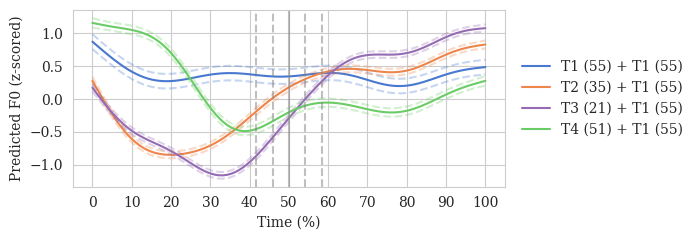

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns

lang = "man"
position = "carryover"
fig, ax = plt.subplots(1, 1, figsize=(6, 2.5), sharex=True, sharey=True)

preceding_tone_values = df[
    (df.lang == lang) &
    (df.position == position) &
    (df.portion_idx<=10)
]["tone_value"].unique()

following_tone_values = df[
    (df.lang == lang) &
    (df.position == position) &
    (df.portion_idx>10)
]["tone_value"].unique()

for idx, target_tone_value in enumerate((following_tone_values[0],)):
    this_df = df[
        (df.lang == lang) &
        (df.position == position) &
        (df.tone_value == target_tone_value)
    ]

    legend_handles = []
    legend_labels = []
    used_colors = []

    for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):

        this_df = df[
            (df.lang == lang) &
            (df.position == position) &
            (df.pair == pair)
        ]

        target_tone_value = this_df[(this_df["portion_idx"]>10)]["tone_value"].values[0]
        target_tone_label = this_df[(this_df["portion_idx"]>10)]["tone_label"].values[0]
        context_tone_value = this_df[(this_df["portion_idx"]<=10)]["tone_value"].values[0]
        context_tone_label = this_df[(this_df["portion_idx"]<=10)]["tone_label"].values[0]
        color = colors[context_tone_value]
        if color in used_colors:
            color = modify_color(color)
        used_colors.append(color)

        line = sns.lineplot(
            ax=ax,
            data=this_df,
            x="portion_idx",
            y="fit",
            color=color,
            label=f"{context_tone_label} ({context_tone_value}) + {target_tone_label} ({target_tone_value})",
        )
        sns.lineplot(
            ax=ax,
            data=this_df,
            x="portion_idx",
            y=[fit+se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )
        sns.lineplot(
            ax=ax,
            data=this_df,
            x="portion_idx",
            y=[fit-se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )

        handle, label = line.get_legend_handles_labels()
        if label and label[0] not in legend_labels:
            legend_handles += handle
            legend_labels += label
            
        ax.set_ylabel("Predicted F0 (z-scored)")


    ax.axvline(x=21/2, color="gray", linestyle="-", alpha=.5)
    ax.axvline(x=10.5+(10.5/12)*1, color="gray", linestyle="--", alpha=.5)
    ax.axvline(x=10.5+(10.5/12)*2, color="gray", linestyle="--", alpha=.5)
    ax.axvline(x=10.5-(10.5/12)*1, color="gray", linestyle="--", alpha=.5)
    ax.axvline(x=10.5-(10.5/12)*2, color="gray", linestyle="--", alpha=.5)
    ax.set_xlabel("Time (%)")
    ax.set_xticks(np.arange(0, 21+2.1, 2.1))
    ax.set_xticklabels(["0", "10", "20", "30", "40", "50", "60", "70", "80", "90", "100"])

    # Add legend to the right-side axis (following) of this row
    if legend_handles:
        ax.legend(
            bbox_to_anchor=(1.01, 0.5),
            loc="center left",
            frameon=False
        )

plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make space for legends
plt.show()
fig.savefig("gamm_visualization_man_carryover_example.png", dpi=500, bbox_inches="tight")

/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/91167252.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/91167252.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/91167252.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/91167252.py:20: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):


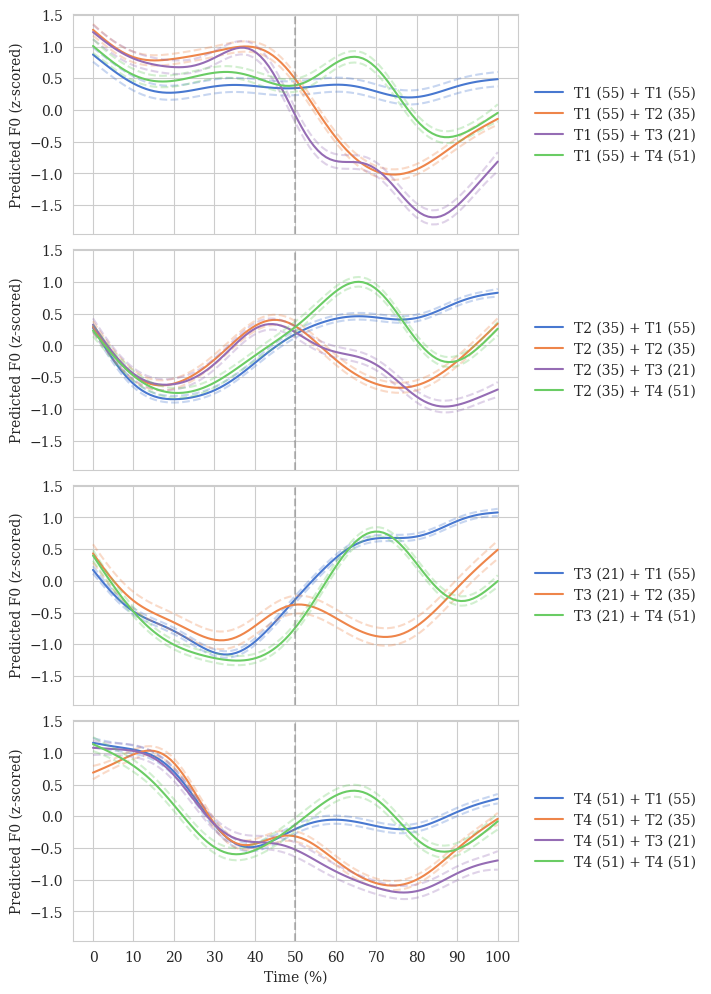

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

lang = "man"
position = "anticipatory"
fig, axes = plt.subplots(4, 1, figsize=(6, 10), sharex=True, sharey=True)

preceding_tone_values = ["55", "35", "21", "51"]

for idx, target_tone_value in enumerate(preceding_tone_values):
    this_df = df[
        (df.lang == lang) &
        (df.position == position) &
        (df.tone_value == target_tone_value)
    ]

    legend_handles = []
    legend_labels = []
    used_colors = []
    for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):

        this_df = df[
            (df.lang == lang) &
            (df.position == position) &
            (df.pair == pair)
        ]

        context_tone_value= this_df[(this_df["portion_idx"]>10)]["tone_value"].values[0]
        context_tone_label = this_df[(this_df["portion_idx"]>10)]["tone_label"].values[0]
        target_tone_value = this_df[(this_df["portion_idx"]<=10)]["tone_value"].values[0]
        target_tone_label = this_df[(this_df["portion_idx"]<=10)]["tone_label"].values[0]
        color = colors[context_tone_value]
        if color in used_colors:
            color = modify_color(color)
        used_colors.append(color)

        line = sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y="fit",
            color=color,
            label=f"{target_tone_label} ({target_tone_value}) + {context_tone_label} ({context_tone_value})",
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit+se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit-se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )

        handle, label = line.get_legend_handles_labels()
        if label and label[0] not in legend_labels:
            legend_handles += handle
            legend_labels += label
            
        axes[idx].set_ylabel("Predicted F0 (z-scored)")


    axes[idx].axvline(x=21/2, color="gray", linestyle="--", alpha=.5)
    axes[-1].set_xlabel("Time (%)")
    axes[-1].set_xticks(np.arange(0, 21+2.1, 2.1))
    axes[-1].set_xticklabels(["0", "10", "20", "30", "40", "50", "60", "70", "80", "90", "100"])

    # Add legend to the right-side axis (following) of this row
    if legend_handles:
        axes[idx].legend(
            bbox_to_anchor=(1.01, 0.5),
            loc="center left",
            frameon=False
        )

plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make space for legends
plt.show()
fig.savefig("gamm_visualization_man_anticipatory.png", dpi=500, bbox_inches="tight")

/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1906081719.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1906081719.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1906081719.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1906081719.py:22: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1906081719.py:22: UserW

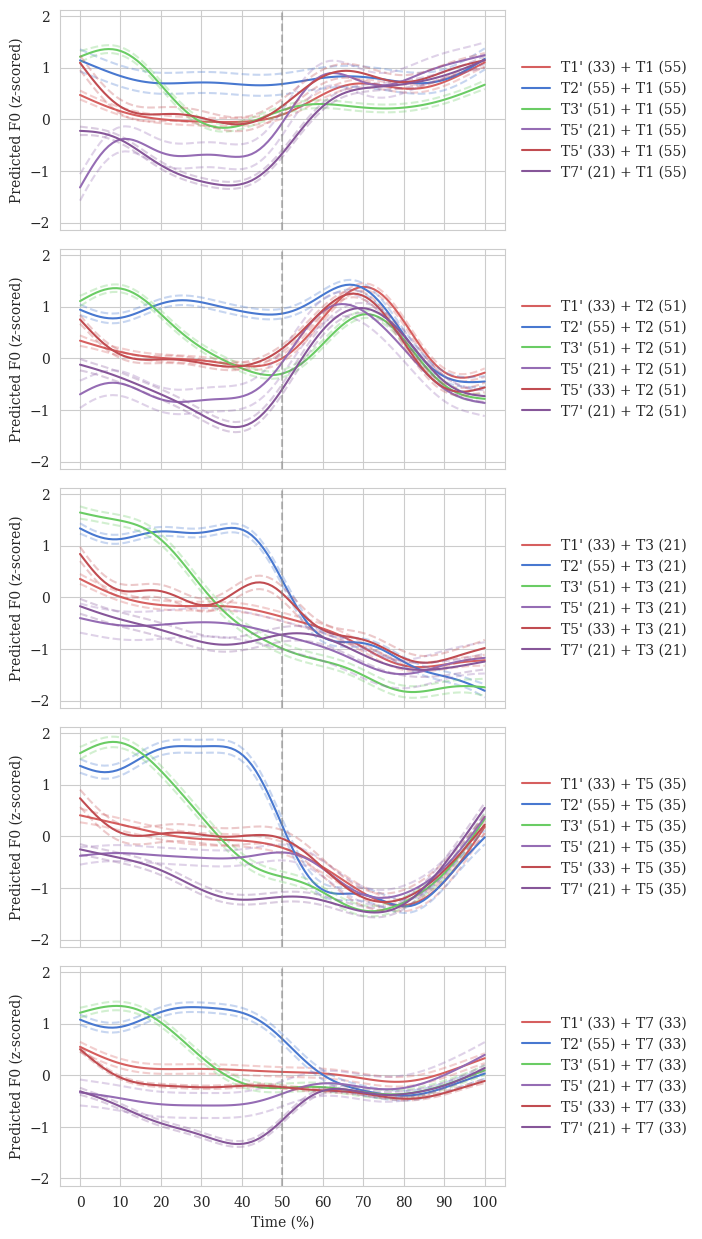

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

lang = "min"
position = "carryover"
fig, axes = plt.subplots(5, 1, figsize=(6, 12.5), sharex=True, sharey=True)


following_tone_values = ['55', '51', '21', '35', '33']


for idx, target_tone_value in enumerate(following_tone_values):
    this_df = df[
        (df.lang == lang) &
        (df.position == position) &
        (df.tone_value == target_tone_value)
    ]

    legend_handles = []
    legend_labels = []
    used_colors = []
    for pair in sorted(this_df[(df.portion_idx>10)]["pair"].unique()):

        this_df = df[
            (df.lang == lang) &
            (df.position == position) &
            (df.pair == pair)
        ]

        target_tone_value = this_df[(this_df["portion_idx"]>10)]["tone_value"].values[0]
        target_tone_label = this_df[(this_df["portion_idx"]>10)]["tone_label"].values[0]
        context_tone_value = this_df[(this_df["portion_idx"]<=10)]["tone_value"].values[0]
        context_tone_label = this_df[(this_df["portion_idx"]<=10)]["tone_label"].values[0]
        color = colors[context_tone_value]
        if color in used_colors:
            color = modify_color(color)
        used_colors.append(color)

        line = sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y="fit",
            color=color,
            label=f"{context_tone_label} ({context_tone_value}) + {target_tone_label} ({target_tone_value})",
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit+se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit-se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )

        handle, label = line.get_legend_handles_labels()
        if label and label[0] not in legend_labels:
            legend_handles += handle
            legend_labels += label
            
        axes[idx].set_ylabel("Predicted F0 (z-scored)")


    axes[idx].axvline(x=21/2, color="gray", linestyle="--", alpha=.5)
    axes[-1].set_xlabel("Time (%)")
    axes[-1].set_xticks(np.arange(0, 21+2.1, 2.1))
    axes[-1].set_xticklabels(["0", "10", "20", "30", "40", "50", "60", "70", "80", "90", "100"])

    # Add legend to the right-side axis (following) of this row
    if legend_handles:
        axes[idx].legend(
            bbox_to_anchor=(1.01, 0.5),
            loc="center left",
            frameon=False
        )

plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make space for legends
plt.show()
fig.savefig("gamm_visualization_min_carryover.png", dpi=500, bbox_inches="tight")

/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1869014215.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1869014215.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1869014215.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):
/var/folders/jq/n323hfzs27s54j8h8b0xq_z40000gn/T/ipykernel_86070/1869014215.py:21: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):


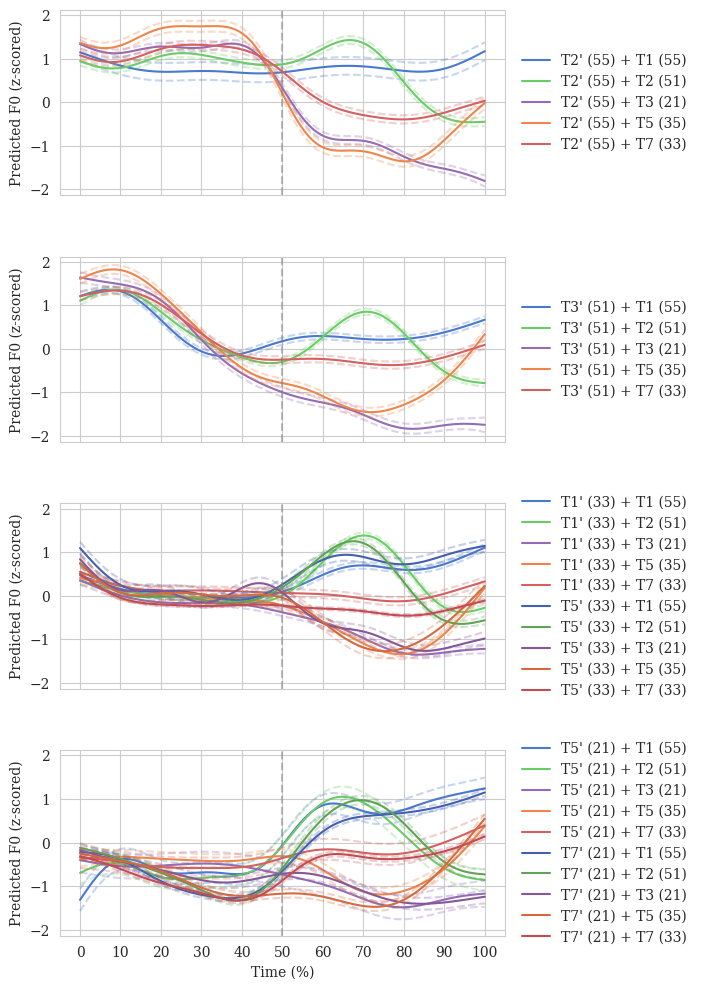

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

lang = "min"
position = "anticipatory"
fig, axes = plt.subplots(4, 1, figsize=(6, 10), sharex=True, sharey=True)

preceding_tone_values = ['55', '51', '33', '21',]

for idx, target_tone_value in enumerate(preceding_tone_values):
    this_df = df[
        (df.lang == lang) &
        (df.position == position) &
        (df.tone_value == target_tone_value)
    ]

    legend_handles = []
    legend_labels = []
    used_colors = []

    for pair in sorted(this_df[(df.portion_idx<10)]["pair"].unique()):

        this_df = df[
            (df.lang == lang) &
            (df.position == position) &
            (df.pair == pair)
        ]

        context_tone_value= this_df[(this_df["portion_idx"]>10)]["tone_value"].values[0]
        context_tone_label = this_df[(this_df["portion_idx"]>10)]["tone_label"].values[0]
        target_tone_value = this_df[(this_df["portion_idx"]<=10)]["tone_value"].values[0]
        target_tone_label = this_df[(this_df["portion_idx"]<=10)]["tone_label"].values[0]
        color = colors[context_tone_value]
        if color in used_colors:
            color = modify_color(color)
        used_colors.append(color)

        line = sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y="fit",
            color=color,
            label=f"{target_tone_label} ({target_tone_value}) + {context_tone_label} ({context_tone_value})",
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit+se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )
        sns.lineplot(
            ax=axes[idx],
            data=this_df,
            x="portion_idx",
            y=[fit-se for fit, se in zip(list(this_df["fit"]),
                                         list(this_df["se"]))],
            ls="--",
            alpha=.3,
            color=color,
        )

        handle, label = line.get_legend_handles_labels()
        if label and label[0] not in legend_labels:
            legend_handles += handle
            legend_labels += label
            
        axes[idx].set_ylabel("Predicted F0 (z-scored)")


    axes[idx].axvline(x=21/2, color="gray", linestyle="--", alpha=.5)
    axes[-1].set_xlabel("Time (%)")
    axes[-1].set_xticks(np.arange(0, 21+2.1, 2.1))
    axes[-1].set_xticklabels(["0", "10", "20", "30", "40", "50", "60", "70", "80", "90", "100"])

    # Add legend to the right-side axis (following) of this row
    if legend_handles:
        axes[idx].legend(
            bbox_to_anchor=(1.01, 0.5),
            loc="center left",
            frameon=False
        )

plt.tight_layout()
plt.subplots_adjust(right=0.85)  # Make space for legends
plt.show()
fig.savefig("gamm_visualization_min_anticipatory.png", dpi=500, bbox_inches="tight")